In [ ]:
import kagglehub
import os
import cv2
from google.colab.patches import cv2_imshow
#Using PyWavelet library
import pywt
import numpy as np



In [ ]:
# Using SimpleITK library
!pip install SimpleITK

In [ ]:
import SimpleITK as sitk
# Using SCIPY library
import scipy

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colorbar as mcolorbar
import matplotlib.colors as mcolors

# **Loading Data**


In [ ]:
# Using Kaggle API
path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")
print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'brain-mri-images-for-brain-tumor-detection' dataset.
Dataset downloaded to: /kaggle/input/brain-mri-images-for-brain-tumor-detection


In [ ]:
# Finding which folders are in the dataset
folders = os.listdir(path)
print("Folders found:", folders)

Folders found: ['no', 'yes', 'brain_tumor_dataset']


In [ ]:
# Loading sample photo with a tumor
tumor_dir = os.path.join(path, 'yes') # directory with tumor image
sample_image_name = os.listdir(tumor_dir)[1]
sample_path = os.path.join(tumor_dir, sample_image_name)

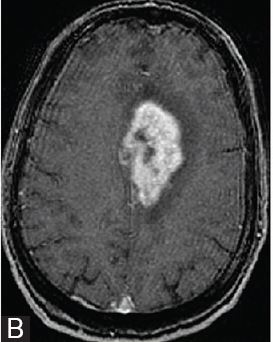

In [ ]:
img = cv2.imread(sample_path)
cv2_imshow(img)

In [ ]:
def gray_resize_image(image):
  size = (224, 224)  # (width, height)
  gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  resized = cv2.resize(gray, size)
  return resized

In [ ]:
# Convert all images to greyscale and resize to the same standard size
tumor_dir = os.path.join(path, 'yes')
def batch_process_images(tumor_dir):
  images = []
  size = (224, 224)  # (width, height)
  for filename in os.listdir(tumor_dir):
    if filename.lower().endswith(('.jpg', '.JPG')):
      img_path = os.path.join(tumor_dir, filename)
      img = cv2.imread(img_path)
      if img is None:
        continue
      resized = gray_resize_image(img)
      images.append(resized)
  print(len(images), "images processed")
  return images


In [ ]:
images = batch_process_images(tumor_dir)

154 images processed


# **Wavelet Denoising**


## **Image 1: Clear Tumor**

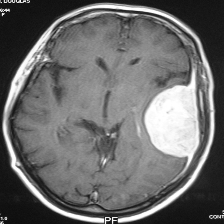

In [ ]:
img_clear_name = 'Y103.jpg'
sample_path_clear = os.path.join(tumor_dir, img_clear_name)
gradyscaled_clear = gray_resize_image(cv2.imread(sample_path_clear))
cv2_imshow(gradyscaled_clear)

In [ ]:
def find_best_wavelet_params(image):
    wavelets = ['bior1.3', 'bior3.5', 'db2']
    thresholds = [10, 30, 60]

    fig, axes = plt.subplots(len(wavelets), len(thresholds), figsize=(15, 12))

    for i, w in enumerate(wavelets):
        for j, t in enumerate(thresholds):
            # Decompose
            coeffs = pywt.dwt2(image, w)
            LL, (LH, HL, HH) = coeffs

            # Soft Thresholding
            LH_t = pywt.threshold(LH, t, mode='soft')
            HL_t = pywt.threshold(HL, t, mode='soft')
            HH_t = pywt.threshold(HH, t, mode='soft')

            # Reconstruct
            res = pywt.idwt2((LL, (LH_t, HL_t, HH_t)), w)
            res = np.clip(res, 0, 255).astype(np.uint8)

            axes[i, j].imshow(res, cmap='gray')
            axes[i, j].set_title(f"{w} | T={t}")
            axes[i, j].axis('off')

    plt.tight_layout()
    plt.show()


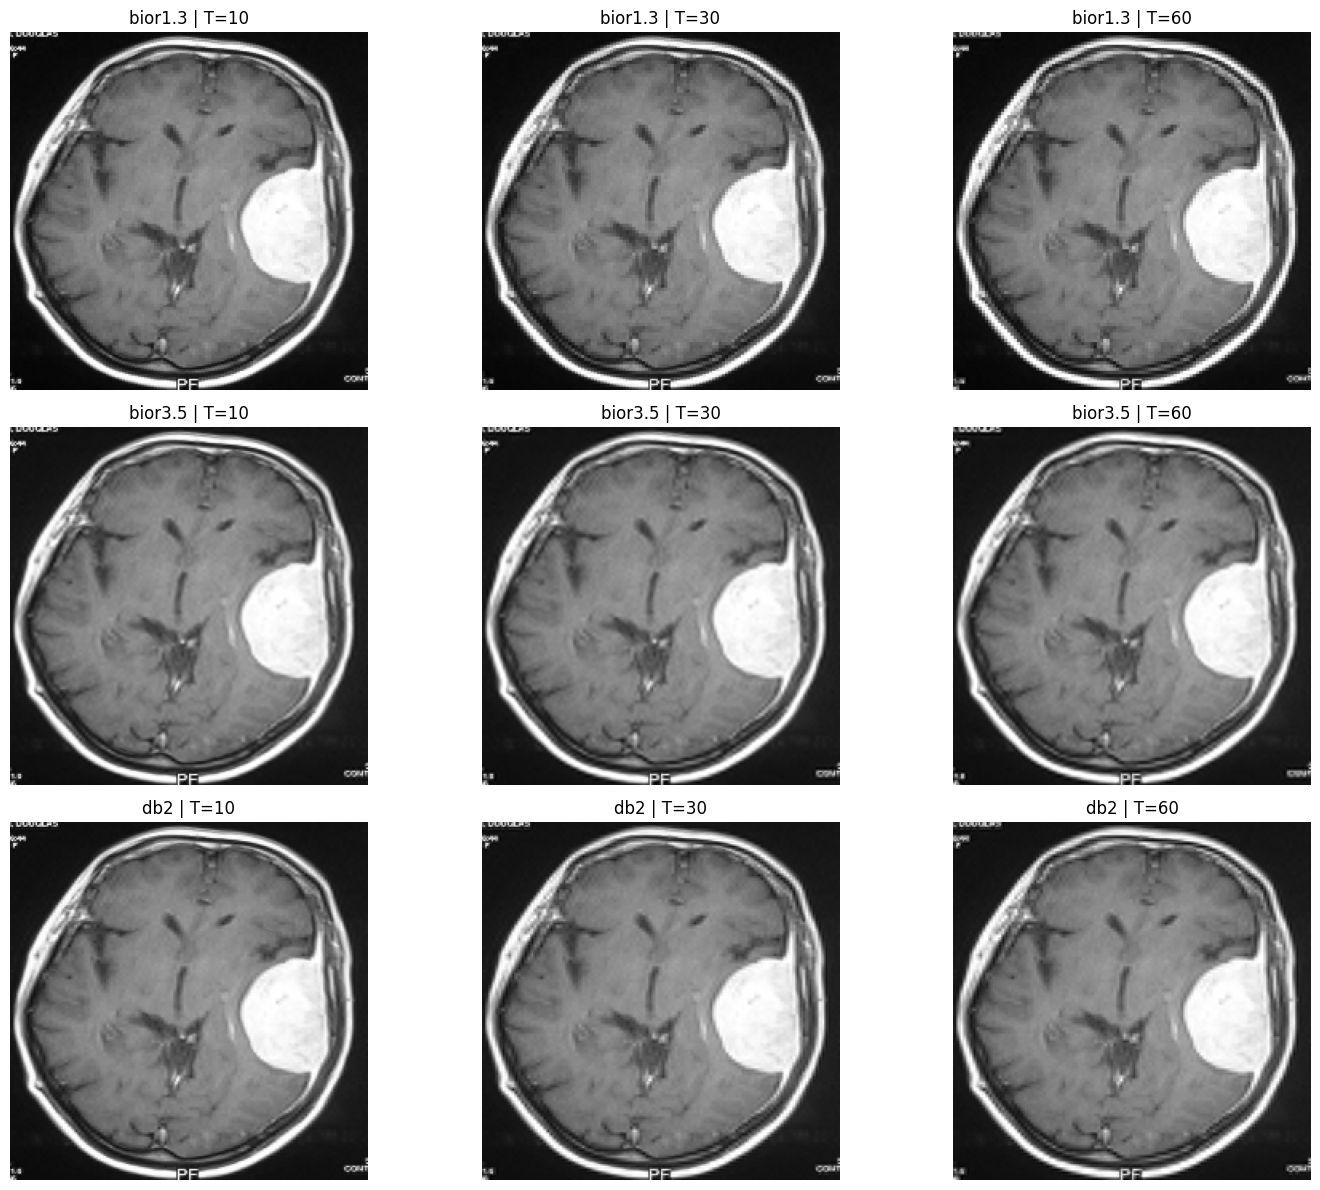

In [ ]:
find_best_wavelet_params(gradyscaled_clear)

In [ ]:
def find_best_wavelet_residuals(image):
    wavelets = ['bior1.3', 'bior3.5', 'db2']
    thresholds = [10, 30, 60]

    fig, axes = plt.subplots(len(wavelets), len(thresholds), figsize=(18, 12))

    # Store residual means for comparison
    residual_means = {}

    for i, w in enumerate(wavelets):
        for j, t in enumerate(thresholds):
            coeffs = pywt.dwt2(image, w)
            LL, (LH, HL, HH) = coeffs
            LH_t = pywt.threshold(LH, t, mode='soft')
            HL_t = pywt.threshold(HL, t, mode='soft')
            HH_t = pywt.threshold(HH, t, mode='soft')
            res = pywt.idwt2((LL, (LH_t, HL_t, HH_t)), w)
            res = np.clip(res, 0, 255).astype(np.uint8)

            residual = cv2.absdiff(image, res)

            residual_means[(w, t)] = residual.mean()

            residual_vis = cv2.normalize(residual, None, 0, 255, cv2.NORM_MINMAX)
            axes[i, j].imshow(residual_vis, cmap='hot')
            axes[i, j].set_title(f"Noise Map: {w} | T={t}")
            axes[i, j].axis('off')

    print("\nResidual Means (higher = more removed):")
    for (w, t), mean in residual_means.items():
        print(f"  {w} | T={t}: {mean:.4f}")

    plt.suptitle("Residual Analysis: If you see the tumor outline, the threshold is TOO HIGH", fontsize=16)
    plt.tight_layout()
    plt.show()

    return residual_means


Residual Means (higher = more removed):
  bior1.3 | T=10: 3.1984
  bior1.3 | T=30: 5.0201
  bior1.3 | T=60: 6.1997
  bior3.5 | T=10: 2.9162
  bior3.5 | T=30: 3.7694
  bior3.5 | T=60: 4.0539
  db2 | T=10: 2.9321
  db2 | T=30: 4.3618
  db2 | T=60: 4.9282


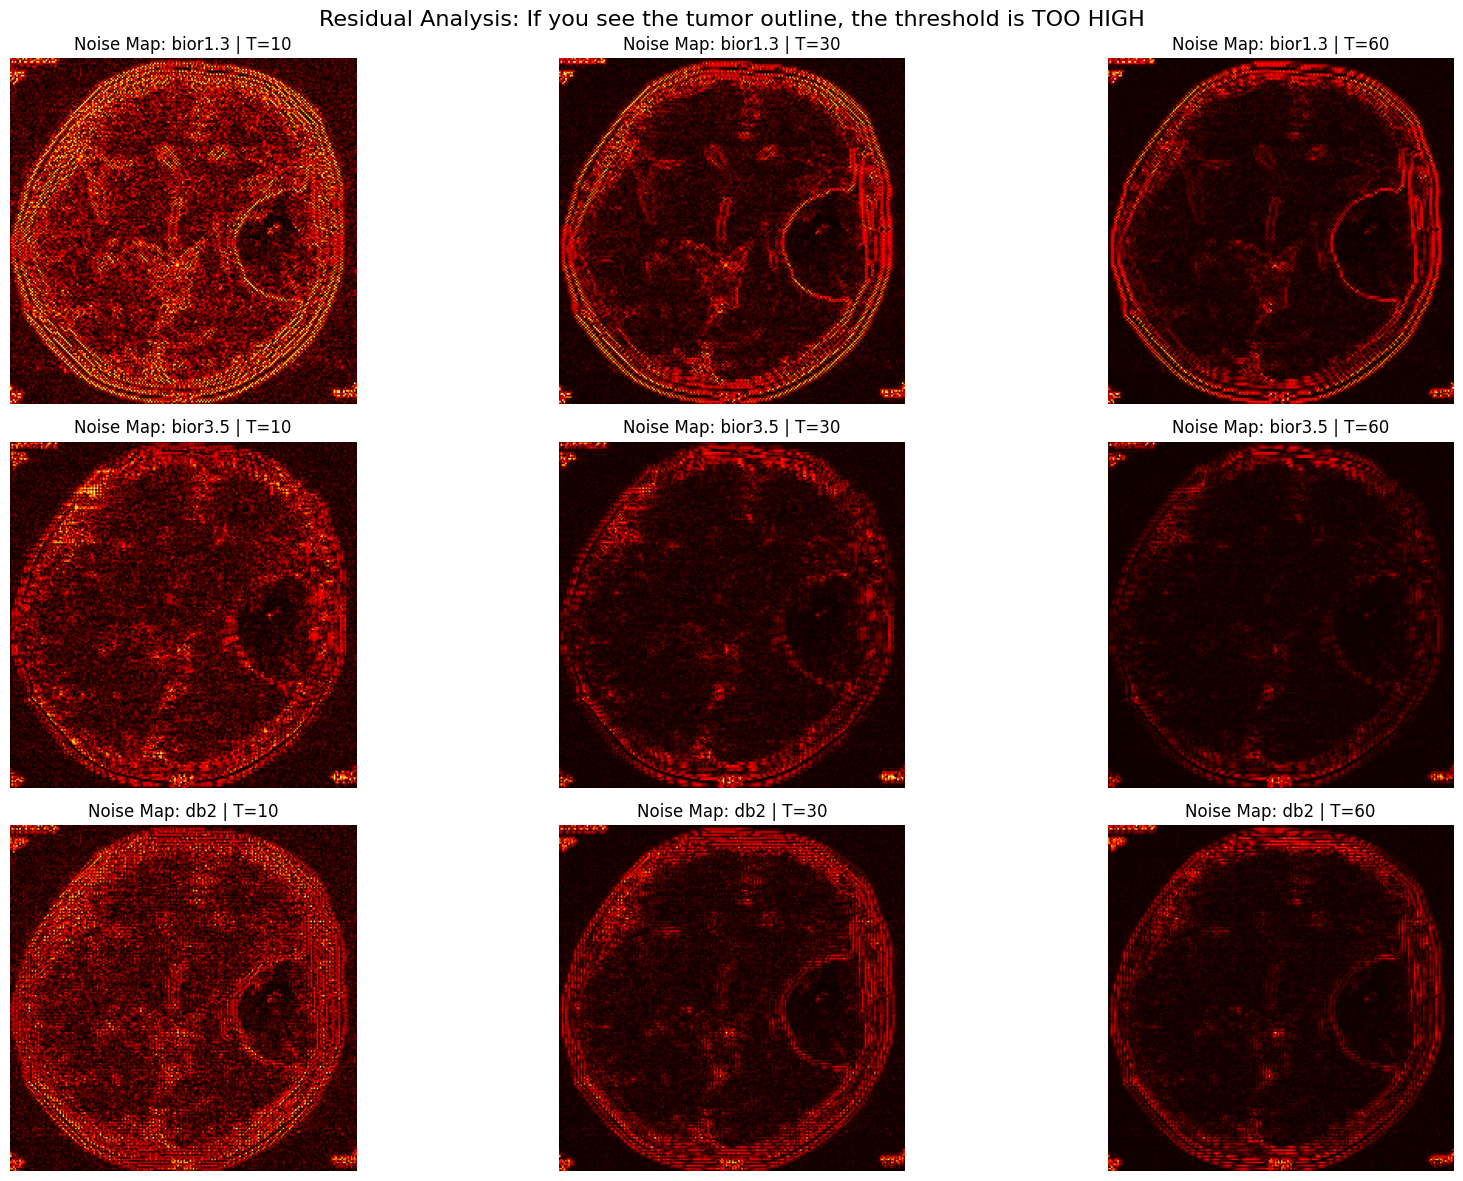

{('bior1.3', 10): np.float64(3.198421556122449),
 ('bior1.3', 30): np.float64(5.020089285714286),
 ('bior1.3', 60): np.float64(6.1997369260204085),
 ('bior3.5', 10): np.float64(2.91617506377551),
 ('bior3.5', 30): np.float64(3.769351881377551),
 ('bior3.5', 60): np.float64(4.053850446428571),
 ('db2', 10): np.float64(2.9321388711734695),
 ('db2', 30): np.float64(4.3618263711734695),
 ('db2', 60): np.float64(4.9282326211734695)}

In [ ]:
find_best_wavelet_residuals(gradyscaled_clear)

Use bior3.5 with threshold = 30

In [ ]:
def wavelet_denoise(image, wavelet='bior3.5', threshold=30):
  coeffs = pywt.dwt2(image, wavelet)
  LL, (LH, HL, HH) = coeffs

  LH = pywt.threshold(LH, threshold, mode='soft')
  HL = pywt.threshold(HL, threshold, mode='soft')
  HH = pywt.threshold(HH, threshold, mode='soft')

  denoised = pywt.idwt2((LL, (LH, HL, HH)), wavelet)
  denoised_uint8 = np.clip(denoised, 0, 255).astype(np.uint8)
  return denoised_uint8


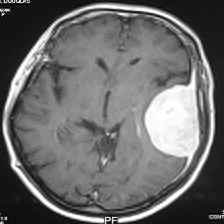

In [ ]:
denoised_img = wavelet_denoise(gradyscaled_clear)
cv2_imshow(denoised_img)

# **Thresholding to Remove Skull**


In [ ]:
def strip_skull(denoised_gray):
    _, threshold = cv2.threshold(denoised_gray, 80, 255, cv2.THRESH_BINARY)

    kernel = np.ones((7, 7), np.uint8)
    closed = cv2.morphologyEx(threshold, cv2.MORPH_CLOSE, kernel, iterations=2)

    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return denoised_gray, None

    largest_contour = max(contours, key=cv2.contourArea)

    mask = np.zeros_like(denoised_gray)
    cv2.drawContours(mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

    blurred = cv2.GaussianBlur(mask.astype(np.float32), (25, 25), 0)
    _, mask = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    mask = mask.astype(np.uint8)

    mask = cv2.erode(mask, kernel, iterations=3)

    # Erode hard to disconnect between fragments, find largest, then dilate back
    k_disconnect = np.ones((15, 15), np.uint8)
    eroded_hard = cv2.erode(mask, k_disconnect, iterations=3)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(eroded_hard, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        largest_blob = np.zeros_like(mask)
        largest_blob[labels == largest_label] = 255

        # Dilate back to recover brain size — match how much we over-eroded
        mask = cv2.dilate(largest_blob, k_disconnect, iterations=3)
        mask = np.clip(mask, 0, 255).astype(np.uint8)


    stripped_brain = cv2.bitwise_and(denoised_gray, denoised_gray, mask=mask)
    return stripped_brain, mask

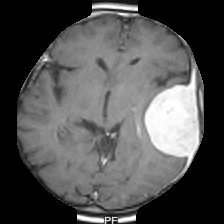

In [ ]:
skull_stripped, mask = strip_skull(denoised_img)
cv2_imshow(skull_stripped)

In [ ]:
def crop_edges(image, mask, margin=10):
    h, w = image.shape
    mask = mask.copy()
    mask[:margin, :] = 0        # top
    mask[h-margin:, :] = 0      # bottom
    mask[:, :margin] = 0        # left
    mask[:, w-margin:] = 0      # right

    cropped = cv2.bitwise_and(image, image, mask=mask)
    return cropped, mask

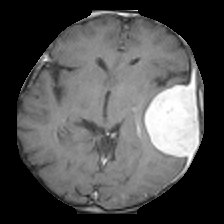

In [ ]:
skull_stripped_cropped = crop_edges(skull_stripped, mask)[0]
cv2_imshow(skull_stripped_cropped)

#***Binary Masking***

Refined seed: (193, 79)


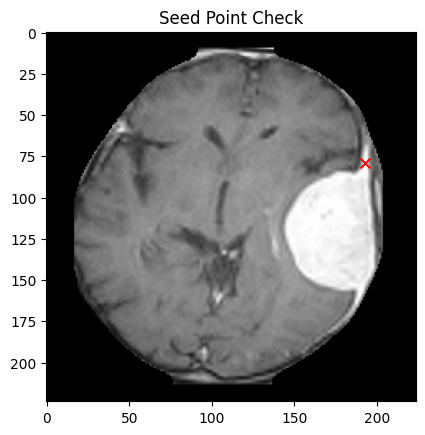

In [ ]:
def get_tumor_seed_refined(skull_stripped_cropped, mask, border_margin=20):
    h, w = skull_stripped_cropped.shape

    border_mask = np.zeros_like(mask)
    border_mask[border_margin:h-border_margin, border_margin:w-border_margin] = 255

    search_region = cv2.bitwise_and(mask, border_mask)

    brain_interior = cv2.bitwise_and(skull_stripped_cropped, skull_stripped_cropped, mask=search_region)

    # 4. Find brightest pixel in the safe interior region
    _, _, _, maxLoc = cv2.minMaxLoc(brain_interior)

    return maxLoc  # (x, y)

_, brain_mask = strip_skull(denoised_img)
refined_seed = get_tumor_seed_refined(skull_stripped, brain_mask, border_margin=20)

print(f"Refined seed: {refined_seed}")

# plot seed on image before running SITK segmentation
plt.imshow(skull_stripped_cropped, cmap='gray')
plt.scatter(refined_seed[0], refined_seed[1], c='red', s=50, marker='x')
plt.title('Seed Point Check')
plt.show()

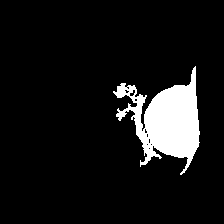

In [ ]:
def run_sitk_segmentation(image_np, seed_point, lower, upper):
    itk_img = sitk.GetImageFromArray(image_np.astype(np.float32))

    # 2. Execute Connected Threshold
    seg_result = sitk.ConnectedThreshold(
        itk_img,
        seedList=[seed_point],
        lower=float(lower),
        upper=float(upper)
    )

    binary_mask = sitk.GetArrayFromImage(seg_result)

    return binary_mask


# Get the seed from existing function
seed = get_tumor_seed_refined(skull_stripped_cropped, mask)

# Run the segmentation
tumor_mask = run_sitk_segmentation(skull_stripped_cropped, seed, lower=150, upper=255)

cv2_imshow(tumor_mask * 255)

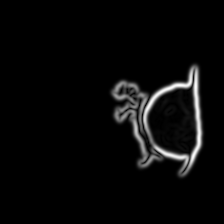

In [ ]:
def get_gradient_magnitude(skull_stripped, tumor_mask_uint8):
    # Apply mask to isolate tumor region only
    tumor_region = cv2.bitwise_and(skull_stripped, skull_stripped,
                                    mask=tumor_mask_uint8)

    # Convert to SITK and run gradient magnitude
    itk_img = sitk.GetImageFromArray(tumor_region.astype(np.float32))

    gradient_filter = sitk.GradientMagnitudeRecursiveGaussianImageFilter()
    gradient_filter.SetSigma(2.0)  # controls edge smoothness
    gradient_itk = gradient_filter.Execute(itk_img)

    gradient_np = sitk.GetArrayFromImage(gradient_itk)

    # Normalize to 0-255
    gradient_norm = cv2.normalize(gradient_np, None, 0, 255, cv2.NORM_MINMAX)
    return gradient_norm.astype(np.uint8)

# --- EXECUTION ---
tumor_mask_uint8 = (tumor_mask * 255).astype(np.uint8)
gradient = get_gradient_magnitude(skull_stripped_cropped, tumor_mask_uint8)
cv2_imshow(gradient)

In [ ]:
def generate_and_display_heatmap(skull_stripped, tumor_mask_uint8, mode='density', window=15):

    if mode == 'distance':
        # Generate distance heatmap
        sitk_mask = sitk.GetImageFromArray(tumor_mask_uint8.astype(np.uint16))
        dist_transform = sitk.GetArrayFromImage(
            sitk.SignedMaurerDistanceMap(
                sitk_mask,
                insideIsPositive=True,
                squaredDistance=False,
                useImageSpacing=False
            )
        )
        dist_transform = np.clip(dist_transform, 0, None)
        if dist_transform.max() > 0:
            display_norm = cv2.normalize(dist_transform, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        heatmap_colored = cv2.applyColorMap(display_norm, cv2.COLORMAP_JET)

    elif mode == 'density':
        # Generate texture heatmap
        tumor_region = cv2.bitwise_and(skull_stripped, skull_stripped,
                                        mask=tumor_mask_uint8).astype(np.float32)
        mean = cv2.boxFilter(tumor_region, ddepth=-1, ksize=(window, window))
        mean_sq = cv2.boxFilter(tumor_region ** 2, ddepth=-1, ksize=(window, window))
        local_std = np.sqrt(np.clip(mean_sq - mean ** 2, 0, None))
        local_std[tumor_mask_uint8 == 0] = 0
        display_norm = cv2.normalize(local_std, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        heatmap_colored = cv2.applyColorMap(display_norm, cv2.COLORMAP_JET)

    # Overlay onto original MRI
    mri_bgr = cv2.cvtColor(skull_stripped, cv2.COLOR_GRAY2BGR)
    overlay = mri_bgr.copy()
    tumor_pixels = tumor_mask_uint8 > 0
    overlay[tumor_pixels] = cv2.addWeighted(
        mri_bgr, 0.4, heatmap_colored, 0.6, 0
    )[tumor_pixels]

    # Display with legend
    fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                              gridspec_kw={'width_ratios': [10, 0.4]})
    heatmap_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)
    axes[0].imshow(heatmap_rgb)
    axes[0].axis('off')

    cmap = plt.cm.jet
    norm = mcolors.Normalize(vmin=0, vmax=display_norm.max())
    cb = mcolorbar.ColorbarBase(axes[1], cmap=cmap, norm=norm, orientation='vertical')

    core_y, core_x = np.unravel_index(np.argmax(display_norm), display_norm.shape)

    if mode == 'density':
        axes[0].set_title('Tumor Activity Heatmap', fontsize=14)
        cb.set_label('Tissue Activity Level', fontsize=11)
        cb.set_ticks([0, display_norm.max() * 0.25, display_norm.max() * 0.5,
                      display_norm.max() * 0.75, display_norm.max()])
        cb.set_ticklabels(['Inactive core\n(uniform/necrotic)', 'Low activity',
                            'Moderate activity', 'High activity',
                            'Active invasion\n(tumor boundary)'])
        axes[0].annotate('Most active\nregion', xy=(core_x, core_y),
                          xytext=(core_x - 80, core_y - 50),
                          fontsize=9, color='white',
                          arrowprops=dict(arrowstyle='->', color='white'))
        fig.text(0.42, 0.01,
                 'Red = active tumor margin (invasion zone)   |   '
                 'Blue = inactive core (necrotic/fluid)   |   '
                 'Yellow = vascular structures',
                 ha='center', fontsize=9, color='gray')

    elif mode == 'distance':
        axes[0].set_title('Tumor Depth Heatmap', fontsize=14)
        cb.set_label('Distance from Tumor Boundary', fontsize=11)
        cb.set_ticks([0, display_norm.max() * 0.25, display_norm.max() * 0.5,
                      display_norm.max() * 0.75, display_norm.max()])
        cb.set_ticklabels(['Tumor boundary\n(edge)', 'Near edge',
                            'Mid tumor', 'Deep tissue',
                            'Tumor center\n(deepest point)'])
        axes[0].annotate('Tumor center', xy=(core_x, core_y),
                          xytext=(core_x - 80, core_y - 50),
                          fontsize=9, color='white',
                          arrowprops=dict(arrowstyle='->', color='white'))
        fig.text(0.42, 0.01,
                 'Red = tumor center (deepest point)   |   Blue = tumor boundary (edge)',
                 ha='center', fontsize=9, color='gray')

    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()

    return overlay, display_norm

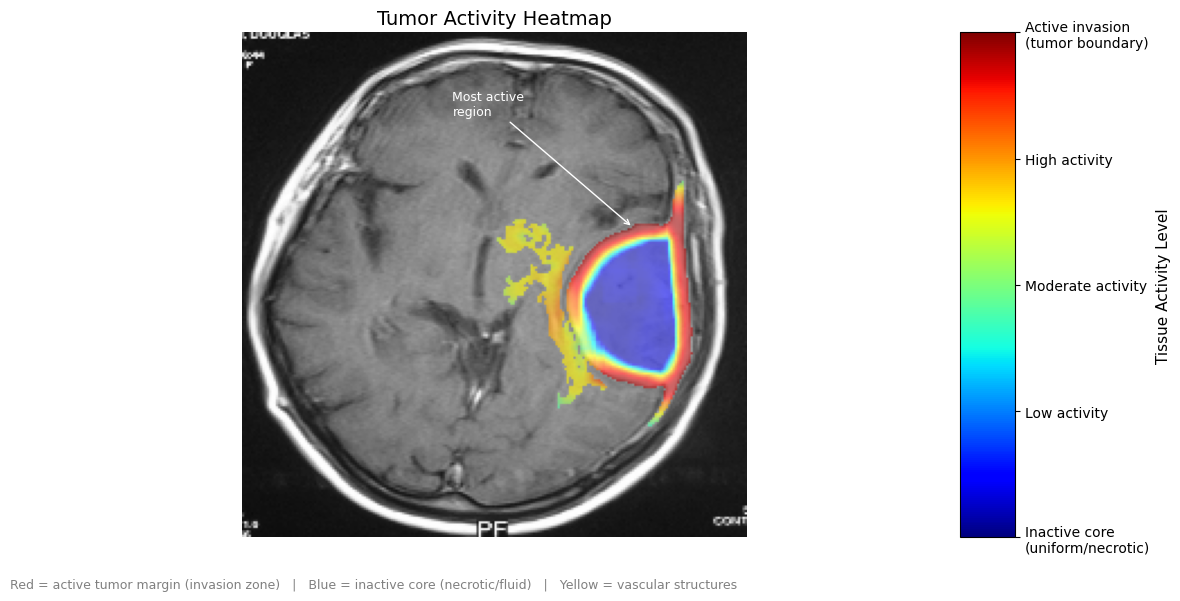

In [ ]:
density_overlay, density_norm = generate_and_display_heatmap(gradyscaled_clear, tumor_mask_uint8, mode='density')



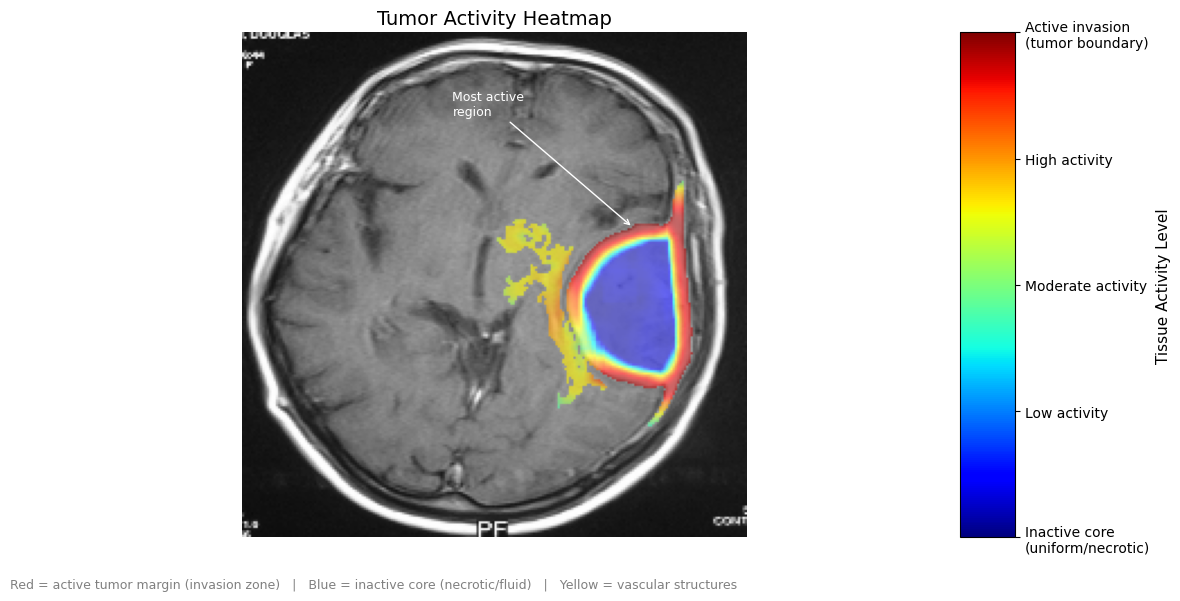

In [ ]:
density_overlay, density_norm = generate_and_display_heatmap(gradyscaled_clear, tumor_mask_uint8, mode='density', window=15)


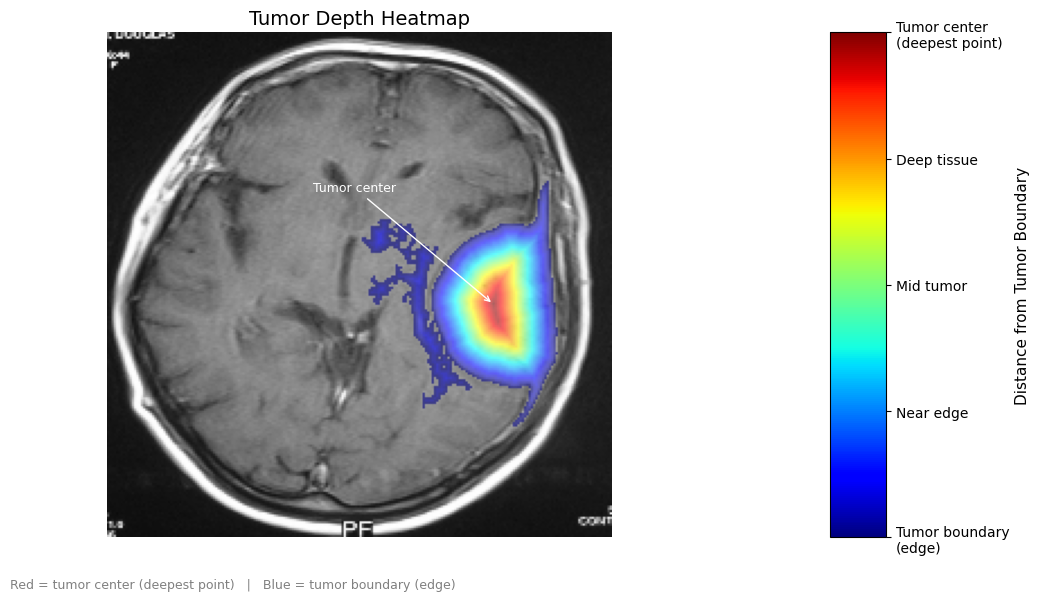

In [ ]:
density_overlay, density_norm = generate_and_display_heatmap(gradyscaled_clear, tumor_mask_uint8, mode='distance')

## **Image 2: Unclear Tumor**

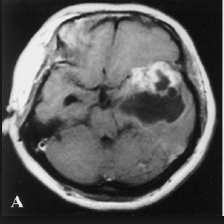

In [ ]:
img_unclear_name = 'Y112.JPG'
sample_path_unclear = os.path.join(tumor_dir, img_unclear_name)
grayscaled_unclear = gray_resize_image(cv2.imread(sample_path_unclear))
cv2_imshow(grayscaled_unclear)

## **Wavelet Denoising**


Residual Means (higher = more removed):
  bior1.3 | T=10: 2.8691
  bior1.3 | T=30: 4.4883
  bior1.3 | T=60: 5.3612
  bior3.5 | T=10: 2.1976
  bior3.5 | T=30: 2.5952
  bior3.5 | T=60: 2.7274
  db2 | T=10: 2.4400
  db2 | T=30: 3.2255
  db2 | T=60: 3.3941


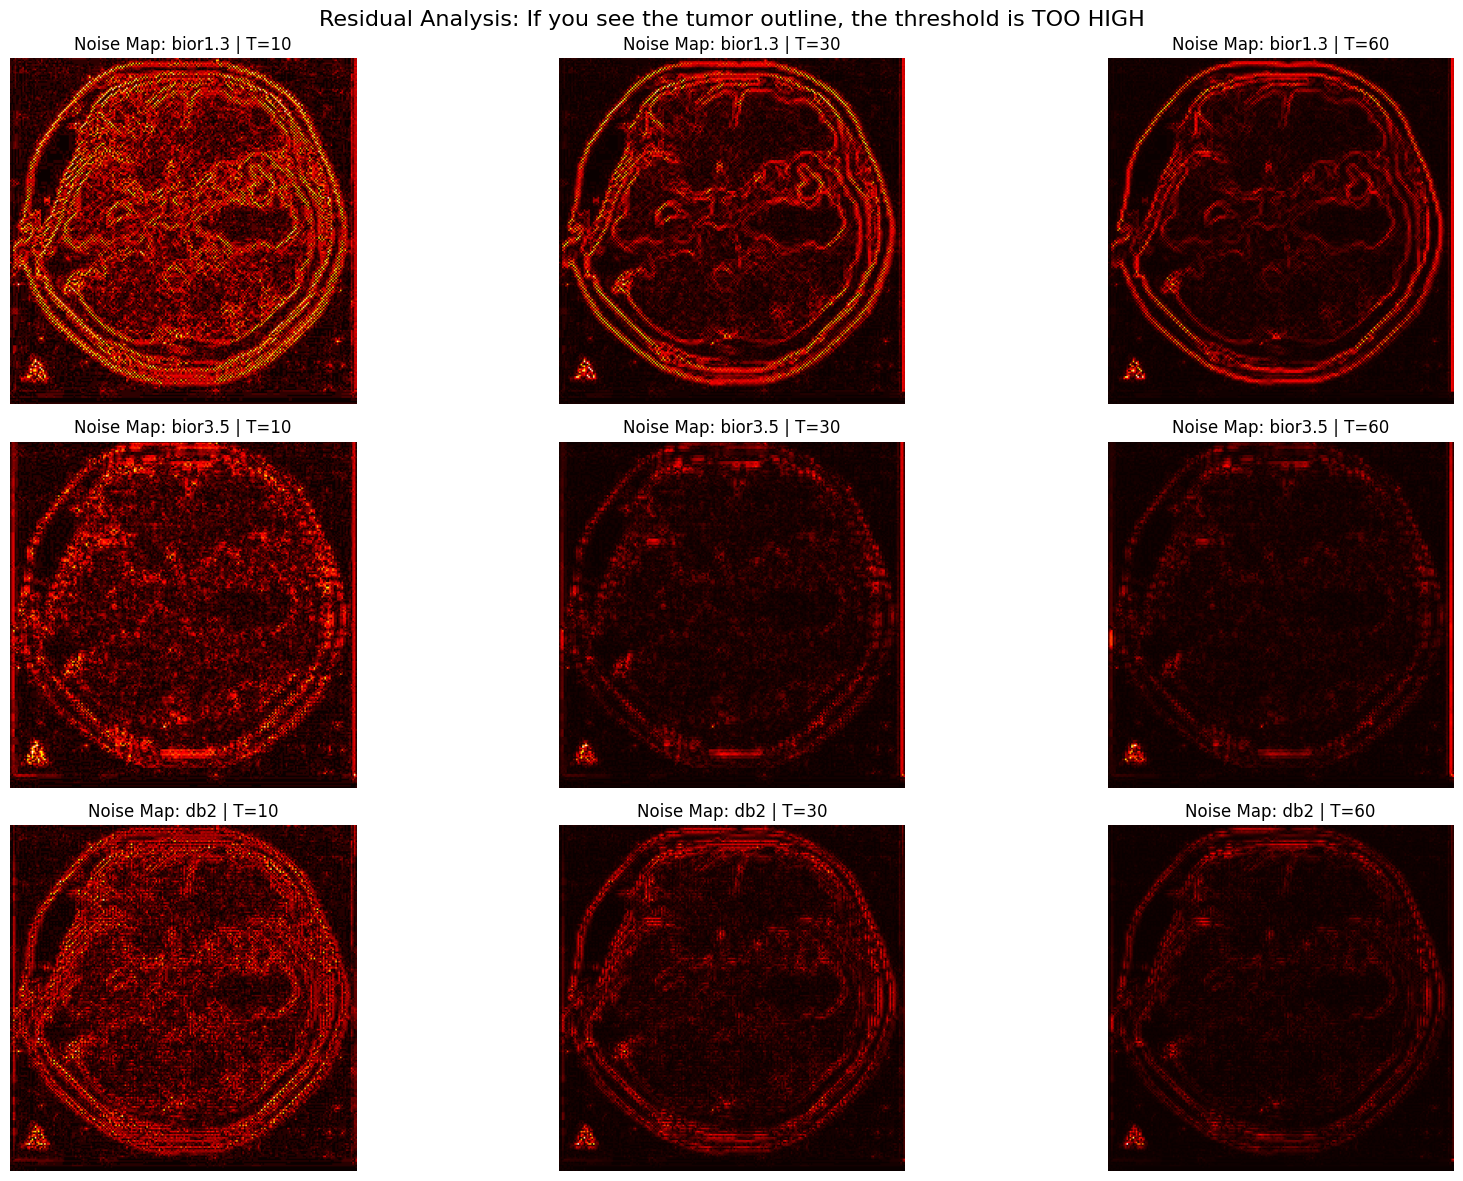

{('bior1.3', 10): np.float64(2.8690808354591835),
 ('bior1.3', 30): np.float64(4.488341039540816),
 ('bior1.3', 60): np.float64(5.361208545918367),
 ('bior3.5', 10): np.float64(2.1975845025510203),
 ('bior3.5', 30): np.float64(2.5952248086734695),
 ('bior3.5', 60): np.float64(2.7274194834183674),
 ('db2', 10): np.float64(2.439991230867347),
 ('db2', 30): np.float64(3.225486288265306),
 ('db2', 60): np.float64(3.3941326530612246)}

In [ ]:
find_best_wavelet_residuals(grayscaled_unclear)

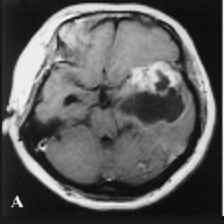

In [ ]:
denoised_img_unclear = wavelet_denoise(grayscaled_unclear)
cv2_imshow(denoised_img_unclear)

## **Skull Stripping**

In [ ]:
def strip_skull(denoised_gray):
    _, threshold = cv2.threshold(denoised_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = np.ones((7, 7), np.uint8)
    closed = cv2.morphologyEx(threshold, cv2.MORPH_CLOSE, kernel, iterations=2)

    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return denoised_gray, None

    largest_contour = max(contours, key=cv2.contourArea)

    mask = np.zeros_like(denoised_gray)
    cv2.drawContours(mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

    blurred = cv2.GaussianBlur(mask.astype(np.float32), (25, 25), 0)
    _, mask = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    mask = mask.astype(np.uint8)

    mask = cv2.erode(mask, kernel, iterations=2)


    k_disconnect = np.ones((15, 15), np.uint8)
    eroded_hard = cv2.erode(mask, k_disconnect, iterations=3)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(eroded_hard, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        largest_blob = np.zeros_like(mask)
        largest_blob[labels == largest_label] = 255

        mask = cv2.dilate(largest_blob, k_disconnect, iterations=3)
        mask = np.clip(mask, 0, 255).astype(np.uint8)

    stripped_brain = cv2.bitwise_and(denoised_gray, denoised_gray, mask=mask)
    return stripped_brain, mask

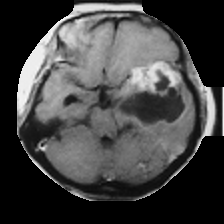

In [ ]:
skull_stripped_unclear, mask_unclear = strip_skull(denoised_img_unclear)
cv2_imshow(skull_stripped_unclear)

Refined seed 2: (154, 66)


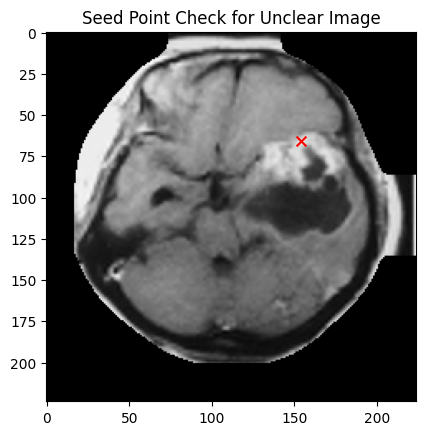

In [ ]:
# Create a mask that only looks at the right half of the brain
h, w = skull_stripped_unclear.shape
quadrant_mask = np.zeros_like(skull_stripped_unclear)
# Focus on the Top-Right (where your tumor is located)
cv2.rectangle(quadrant_mask, (w//2, 0), (w, h//2 + 50), 255, -1)

refined_seed2  = get_tumor_seed_refined(skull_stripped_unclear, quadrant_mask)

print(f"Refined seed 2: {refined_seed2}")


plt.imshow(skull_stripped_unclear, cmap='gray')
plt.scatter(refined_seed2[0], refined_seed2[1], c='red', s=50, marker='x')
plt.title('Seed Point Check for Unclear Image')
plt.show()

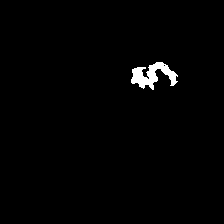

In [ ]:
tumor_mask_uncleared = run_sitk_segmentation(skull_stripped_unclear,refined_seed2, lower=180, upper=255)
cv2_imshow(tumor_mask_uncleared * 255)

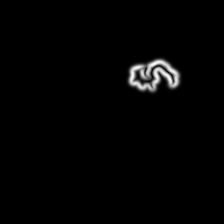

In [ ]:
tumor_mask_unclear_uint8 = (tumor_mask_uncleared * 255).astype(np.uint8)
gradient_unclear = get_gradient_magnitude(skull_stripped_unclear, tumor_mask_unclear_uint8)
cv2_imshow(gradient_unclear)

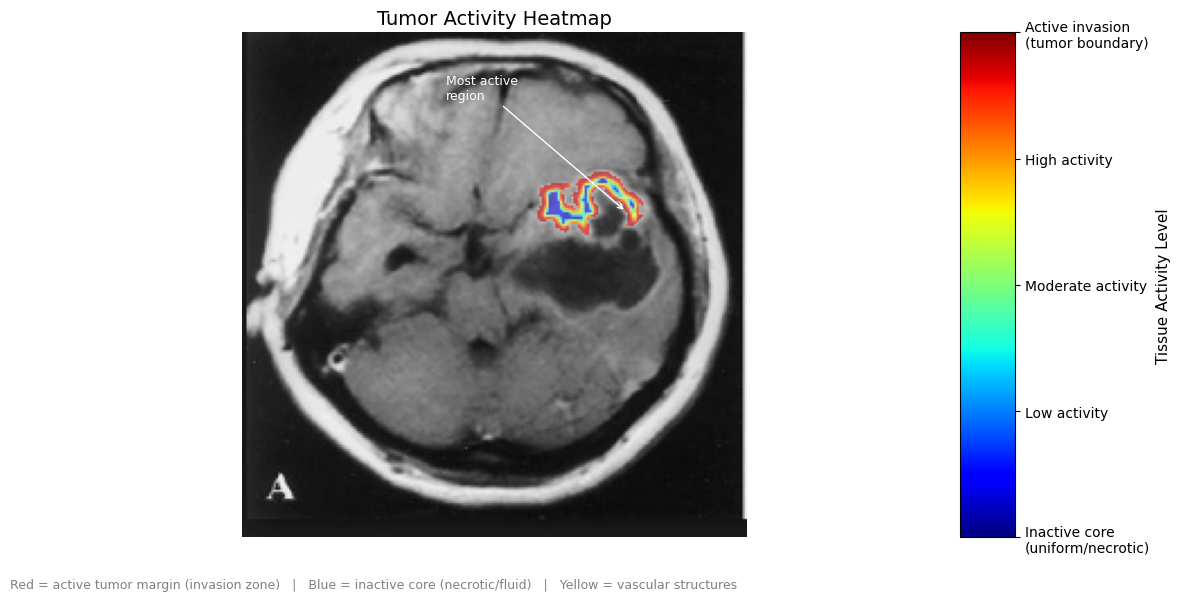

In [ ]:
density_overlay_unclear, density_norm_unclear = generate_and_display_heatmap(
    grayscaled_unclear, tumor_mask_unclear_uint8, mode='density', window=6)

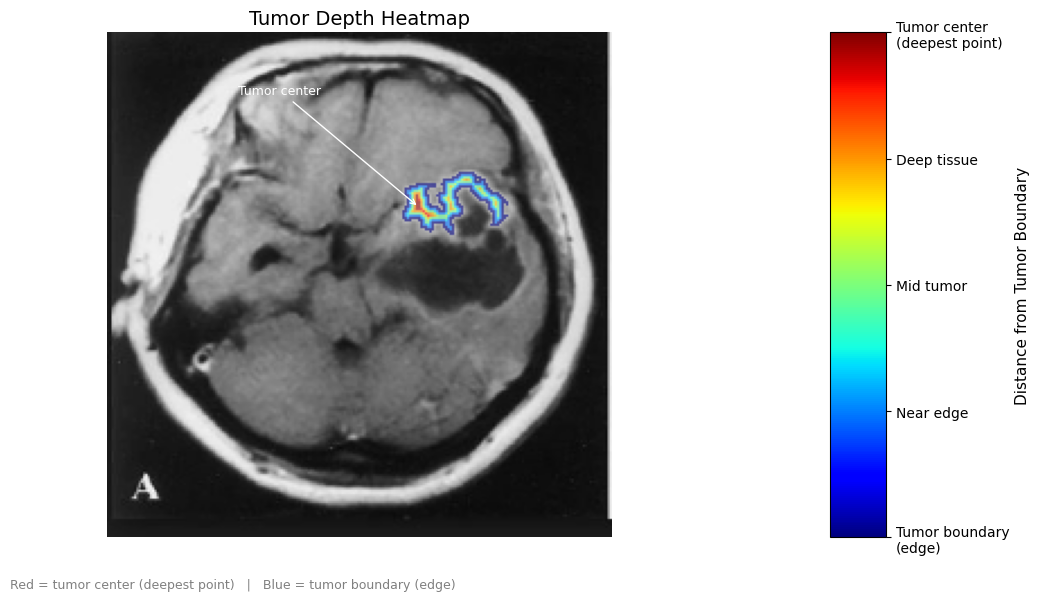

In [ ]:
density_overlay_unclear, density_norm_unclear = generate_and_display_heatmap(
    grayscaled_unclear, tumor_mask_unclear_uint8, mode='distance')